# Currents, barotropic streamfunction, SSH variability

Re-create [Kiss et al 2020](https://doi.org/10.5194/gmd-13-401-2020) figs 16, 17, 21, 22, 24

See
- https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/BarotropicStreamfunction/BarotropicStreamfunction.ipynb
- https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/Southwest_Atlantic/Southwest_atlantic_analysis_v3.ipynb

See
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/15
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/18

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/"
nbname = "Currents_streamfunction_variability.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file, get_exptname_from_path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()  # conda env workaround; no-op on healthy envs

import os
import xarray as xr
import gsw
import intake
import dask
from dask.distributed import Client
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from shapely import geometry
import calendar
import cftime
import textwrap
import numpy as np
from tqdm.notebook import tqdm
import xgcm
from scipy.io import loadmat

In [5]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [6]:
xr.set_options(keep_attrs=True);

In [7]:
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too

In [8]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:37507,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38071,Total threads: 1
Dashboard: http://127.0.0.1:42963/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:37711,


In [9]:
IAF = esm_file.find('iaf') > 0
IAF

False

In [10]:
om3exptname = get_exptname_from_path(esm_file)
om3exptname

'MC_8km_jra_ryf-test2-expt-c349f800'

## Load ACCESS-OM3 data from ESM datastore

In [11]:
fields = { # key is OM3 name, value is OM2 name
    # "speed": None,  # presumably includes high-frequency motion, so differs from sqrt(uo**2 + vo**2) calculated from monthly means
    "uo": "u",
    "vo": "v",
    "umo_2d": "tx_trans_int_z",
    # "vmo_2d": "ty_trans_int_z",
    "zos": "sea_level",
    "zossq": "sea_level_sq",
}

depths = [0, 1000]

In [12]:
exptname = get_exptname_from_path(esm_file)

In [13]:
catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                esm_file,
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm1-d968c801/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm2-5dc49da6/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm3-da330542/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm4-9fd08880/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm5-9b5dbfa9/datastore.json',
            ]
catalogs

['/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json']

In [14]:
om3datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'MC_8km_jra_ryf-test2-expt-c349f800': <datastore catalog with 32 dataset(s) from 3843 asset(s)>}

In [15]:
open_kwargs = dict(
    # chunks={"xh": -1, "yh": -1},
    # chunks={"time": -1},
    decode_timedelta=True,
    use_cftime=True
)
if model_name == "ACCESS-CM3":
    open_kwargs["chunks"] = {"time": 1}  # CM3 stores yearly files

om3data = {
    vname: {expt: ds.search(variable=vname, frequency="1mon").to_dask(
                xarray_open_kwargs = open_kwargs
            )[vname]
            for expt, ds in om3datastores.items()
          }
    for vname in fields
    }

# uo/vo are only plotted at specified depths; select them now (before the time mean)
# so only those levels are read, not all 75
for vname in ["uo", "vo"]:
    for expt in om3data[vname]:
        om3data[vname][expt] = om3data[vname][expt].sel(z_l=depths, method="nearest")

# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3data.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass

if IAF:
    for vname, d in om3data.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

## Load data from ACCESS-OM2
use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7

In [16]:
if model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    om2exptname = 'cj877'  # CM2 control archive on /g/data/p73 (same reference as pPV.ipynb)
    om2datastores = {om2exptname: None}  # single-entry, so downstream `for expt in om2datastores:` loops work unchanged
else:
    data_name = 'ACCESS-OM2'
    if IAF:
        om2exptnames = [
                        '025deg_jra55_iaf_omip2_cycle1',
                        '01deg_jra55v140_iaf',
                       ]
    else:
        om2exptnames = [
                        '025deg_jra55_ryf9091_gadi', # monthly temp only for 1900-1903, and 2300-, with annual data in the gap
                        '01deg_jra55v13_ryf9091',
                       ]
    om2datastores = {n: intake.cat.access_nri[n] for n in om2exptnames}

In [17]:
if model_name == "ACCESS-CM3":
    # Reference: ACCESS-CM2 cj877 control archive (same source as pPV.ipynb and
    # Overturning_in_ACCESS_OM3.ipynb). Limit to the last 600 months to match
    # the CM3 record length; each cj877 file holds 6 months.
    from pathlib import Path
    cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")
    n_months = 600

    def _load_cm2(varname):
        # cj877 archive files use either an "ocean-3d-" or "ocean-2d-" prefix
        # depending on the variable (u/v are 3D; tx_trans_int_z/sea_level(_sq)
        # are already vertically-integrated/surface 2D fields) -- try both
        # rather than hardcoding one.
        files = sorted(cm2_dir.glob(f"ocean-3d-{varname}-1-monthly-mean-ym_*.nc"))
        if not files:
            files = sorted(cm2_dir.glob(f"ocean-2d-{varname}-1-monthly-mean-ym_*.nc"))
        if not files:
            raise FileNotFoundError(
                f"No cj877 monthly files found for {varname!r} (tried both ocean-3d- and ocean-2d- prefixes)"
            )
        files = files[-((n_months + 5) // 6):]
        ds = xr.open_mfdataset(
            files,
            combine="by_coords",
            parallel=True,
            chunks={"time": 1, "xt_ocean": -1, "yt_ocean": -1, "st_ocean": -1},
            decode_timedelta=True,
            use_cftime=True,  # cj877 model years (~453-503) can't be datetime64
            data_vars="minimal", coords="minimal", compat="override",
        )
        return ds[varname]

    om2data = { vname: {om2exptname: _load_cm2(vname)} for vname in fields.values() }

    # Relabel the CM2 control-run times onto the CM3 time axis so the panels can
    # share the x-axis (same approach as Overturning_in_ACCESS_OM3.ipynb) — this
    # also avoids mixing cftime and datetime64 axes, which matplotlib can't share.
    cm3_time = next(iter(om3data[next(iter(fields))].values())).time
    for vname, dd in om2data.items():
        for expt, da in dd.items():
            n = min(da.sizes["time"], cm3_time.sizes["time"])
            if da.sizes["time"] != cm3_time.sizes["time"]:
                print(f"Aligning {expt} {vname} with last {n} time steps")
            dd[expt] = (da.isel(time=slice(-n, None))
                          .assign_coords(time=("time", cm3_time.isel(time=slice(-n, None)).values)))

else:
    def _load_om2(ds, vname):
        cat = ds.search(variable=vname, frequency="1mon", variable_cell_methods="time: mean")
        if len(cat) > 1:  # e.g. 025deg_jra55_ryf9091_gadi has 2d fields in two file_ids: use the one with most files
            cat = cat.search(file_id=cat.df.file_id.value_counts().idxmax())
        return cat.to_dask(
                    xarray_open_kwargs = dict(
                        chunks={"xt_ocean": -1, "yt_ocean": "auto", "st_ocean" : -1},  # remove "yt_ocean": -1 for resolution finer than 25km
                        decode_timedelta=True
                    )
                )[vname]

    om2data = {vname: dict() for vname in fields.values()}
    for vname in fields.values():
        for expt, ds in om2datastores.items():
            try:
                om2data[vname][expt] = _load_om2(ds, vname)
            except ValueError:  # e.g. sea_level_sq is not in the OM2 RYF runs
                print(vname, 'not loaded for', expt)
    # # also load tx_trans_gm if available - commented out: including GM messes up the barotropic streamfunction plots
    # vname = 'tx_trans_gm'
    # om2data[vname] = dict()
    # for expt, ds in om2datastores.items():
    #     try:
    #         om2data[vname][expt] = ds.search(variable=vname, frequency="1mon", variable_cell_methods="time: mean").to_dask(
    #                 xarray_open_kwargs = dict(
    #                     chunks={"xt_ocean": -1, "yt_ocean": "auto", "st_ocean" : -1},  # remove "yt_ocean": -1 for resolution finer than 25km
    #                     decode_timedelta=True
    #                 )
    #             )[vname]
    #     except:
    #         print(vname, 'not loaded for', expt)

    if IAF:
        for vname, d in om2data.items():
            for expt in d:
                try:
                    d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
                except KeyError:
                    pass

# u/v are only plotted at specified depths; select them now (before the time mean)
# so only those levels are read
for vname in ["u", "v"]:
    for expt in om2data[vname]:
        om2data[vname][expt] = om2data[vname][expt].sel(st_ocean=depths, method="nearest")

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

sea_level_sq not loaded for 025deg_jra55_ryf9091_gadi
sea_level_sq not loaded for 01deg_jra55v13_ryf9091


## Load observations

In [18]:
def xtile(ds_in, x="longitude"):
    """
    Tile dataset in longitude to cover MOM6 range.
        ds_in: input dataset, assumed 2d with x coordinate second
        x: name of x coordinate, defaults to "longitude"
    """
    x_tiled = np.tile(ds_in[x], 2)
    x_tiled[:ds_in[x].size] -= 360
    ds_out = xr.Dataset(
        attrs=ds_in.attrs,
        coords=dict(ds_in.coords) | {x: x_tiled},
        data_vars={k: (v.dims, np.tile(v, (1,2))) for k, v in ds_in.items()}
    )
    for k, v in ds_out.coords.items():
        v.attrs = ds_in[k].attrs
    for k, v in ds_out.items():
        v.attrs = ds_in[k].attrs
    return ds_out

#### Drifters surface speed
Drifter surface speed data from Kiss et al fig 24 was from [Laurindo et al 2017](http://dx.doi.org/10.1016/j.dsr.2017.04.009), downloaded in 2017.

Here we use an updated 2025 version from http://www.aoml.noaa.gov/phod/dac/dac_meanvel.php instead.

In [19]:
drifters_ds = xtile(
    xr.open_dataset(
        '/g/data/ik11/observations/Laurindo_et_al_surface_current/v3.11/drifter_annualmeans.nc'
    ).transpose('latitude', 'longitude'))

# calculate speed
drifters_ds["speed"] = np.sqrt( drifters_ds['U']**2 + drifters_ds['V']**2 ).compute()
drifters_ds["speed"].attrs = drifters_ds["U"].attrs | {'units': 'm s-1', 'long_name': 'Surface speed'}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x147541403590>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14750e5033e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14750e501490>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14750e503560>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14750e4fe930>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14750e4724b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14750d0a6000>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


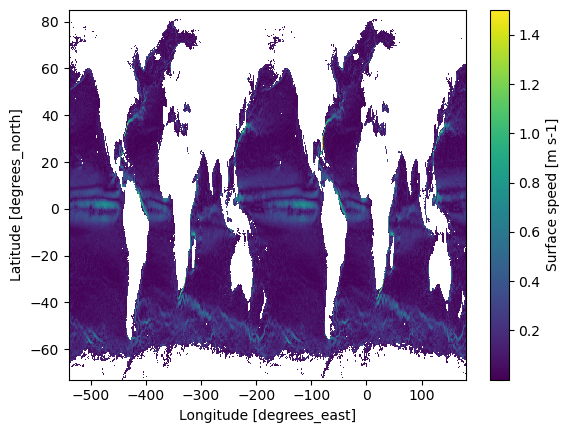

In [20]:
drifters_ds["speed"].plot()

#### ANDRO deep currents

Ollitrault, M. and Rannou, J.-P. (2013). ANDRO: An Argo-based deep displacement dataset. Journal of Atmospheric and Oceanic Technology, 30(4):759–788.
http://dx.doi.org/10.1175/JTECH-D-12-00073.1

2026 release: https://doi.org/10.17882/47077 and https://www.seanoe.org/data/00360/47077/

**BUG:** data seems misaligned with land in places

In [21]:
andro_ds = xtile(
    xr.open_dataset(
        '/g/data/ik11/observations/ANDRO_Argo_displacements/2026/127689.nc'
    ).transpose('latitude', 'longitude'))

# calculate speed
andro_ds["speed"] = np.sqrt( andro_ds['mean_u']**2 + andro_ds['mean_v']**2 )/100  # convert cm/s to m/s
andro_ds["speed"].attrs = andro_ds["mean_u"].attrs | {'units': 'm s-1', 'long_name': 'Speed at 1000m'}
del andro_ds["speed"].attrs["Units"]
del andro_ds["speed"].attrs["Name"]

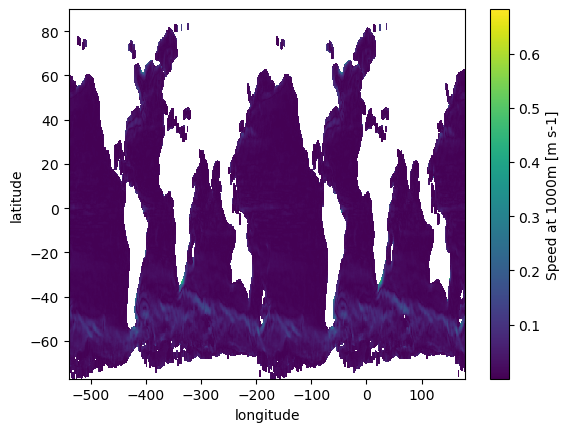

In [22]:
andro_ds["speed"].plot()

#### Barotropic streamfunction

Observational estimate from [Colin de Verdiere and Ollitrault (2016)](https://doi.org/10.1175/jpo-d-15-0046.1).

In [23]:
psi_data = loadmat('/g/data/ik11/from_hh5_tmp/cosima/observations_new/original/psi_barotropic.mat')
psi_ds = xtile(xr.Dataset(
             coords={"latitude": psi_data["lat_p"][0, :],
                     "longitude": psi_data["lon_p"][0, :]},
             data_vars={"psi": (("latitude", "longitude"), psi_data["psi"]/1e6)} # convert to Sv
            ))
psi_ds["psi"].attrs={'units': 'Sv', 'long_name': 'Barotropic streamfunction'}
psi_ds.attrs = {'author': 'Observational estimate from Colin de Verdiere and Ollitrault (2016) https://doi.org/10.1175/jpo-d-15-0046.1'}

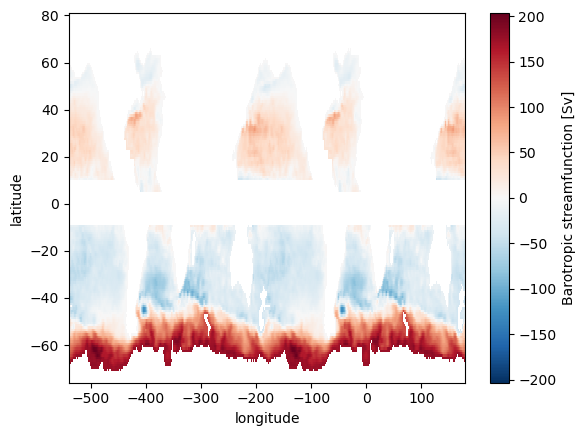

In [24]:
psi_ds["psi"].plot()

#### SSH standard deviation

SSH standard deviation in Kiss et al 2020 used `/g/data/ik11/from_hh5_tmp/cosima/observations/original/AVISO_Mean_Std/aviso_ssh_monthly_anom_clim9314_GMSLtrend_removed.timstd.nc` which was based on monthly anomalies and calculated in 2018 from data that might have been from 2014.

Here we use a recent CMEMS product instead (also used in [SSH.ipynb](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/blob/main/notebooks/SSH.ipynb)), which also gives us the option of using daily data, to capture more of the variability: https://doi.org/10.48670/moi-00148

**TODO: filter out mean sea level trend due to climate change?**

In [25]:
monthly = '/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1M-m_202411/*/*.nc'
daily = '/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/*/*/*.nc'

In [26]:
%%time
cmems_files = daily # slow (~14 min with 28 cores)
# cmems_files = monthly # quick (16 s)
# Each day is a separate .nc file, so we do all we can to speed this up...
cmems_ds = xr.open_mfdataset(
    cmems_files,
    parallel=True,
    chunks='auto',
    combine='nested',
    concat_dim='time',
    compat='override',
    coords='minimal',
    data_vars='minimal',
).convert_calendar("proleptic_gregorian", use_cftime=True)

# actual standard deviation calculation is below, after trimming time

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x146cf0a1b830>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14dc607d40b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504ed09caa0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504e6c3f770>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1522370ab890>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15194f6a5010>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1512cfa814f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15194b257740>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1512cb827d70>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


CPU times: user 6min 57s, sys: 3min 54s, total: 10min 52s
Wall time: 12min 25s


## Set time range and calculate time average

### Trim to a consistent time range

In [27]:
from model_agnostic import years_window, year_slice

nyears = 30 # get (at most) nyears from end of common data

if IAF or model_name == "ACCESS-CM3":
    # find largest overlapping time range
    # TODO: also trim to match the other obs datasets?

    # earliest end date in data
    datastop = np.min([ om3data['uo'][e].time.values[-1] for e in om3data['uo'].keys() ])
    datastop = min(datastop, np.min([ om2data['u'][e].time.values[-1] for e in om2data['u'].keys() ]))
    datastop = min(datastop, cmems_ds.time.values[-1])

    # latest start date in data
    datastart = np.max([ om3data['uo'][e].time.values[0] for e in om3data['uo'].keys() ])
    datastart = max(datastart, np.max([ om2data['u'][e].time.values[0] for e in om2data['u'].keys() ]))
    datastart = max(datastart, cmems_ds.time.values[0])

    print('common data range:', datastart, 'to', datastop)

    datastart = np.max([
        datastart, 
        cftime.datetime(cftime.to_tuple(datastop)[0]-nyears+1, 1, 1, calendar=datastop.calendar)
    ])

    # bracket to start/end of year
    datestart = cftime.datetime(cftime.to_tuple(datastart)[0],  1, 1, calendar=datastop.calendar)
    datestop  = cftime.datetime(cftime.to_tuple(datastop)[0], 12, 31, 23, 59, 59, calendar=datastop.calendar)

    print('data range used:  ', datestart, 'to', datestop)

    timeslice = slice(datestart, datestop)
    period = f"{datestart.strftime('%Y-%m')} - {datestop.strftime('%Y-%m')}"
    om3timeslice, om3period = timeslice, period
    om2timeslice = {e: timeslice for e in om2data['u']}
    om2period = {e: period for e in om2data['u']}
    obstimeslice, obsperiod = timeslice, period
else:
    # RYF: model calendar years are arbitrary, so don't overlap them with the obs.
    # Use the last (up to) nyears complete years of OM3, the same model years of each
    # OM2 RYF control where it has them, and the last nyears of the obs.
    om3window = years_window(om3data['uo'][om3exptname].time, nyears)
    om3timeslice = year_slice(om3window)
    om3period = f"{om3window[0]} - {om3window[1]}"
    om2timeslice, om2period = dict(), dict()
    for e in om2data['u']:
        w = years_window(om2data['u'][e].time, nyears, within=om3window)
        om2timeslice[e] = year_slice(w)
        om2period[e] = f"{w[0]} - {w[1]}"
    w = years_window(cmems_ds.time, nyears)
    obstimeslice = year_slice(w)
    obsperiod = f"{w[0]} - {w[1]}"

print('ACCESS-OM3:', om3period, '| OM2/CM2:', om2period, '| obs:', obsperiod)

ACCESS-OM3: 1900 - 1909 | OM2/CM2: {'025deg_jra55_ryf9091_gadi': '1900 - 1903', '01deg_jra55v13_ryf9091': '1950 - 1979'} | obs: 1996 - 2020


In [28]:
# trim everything to timeslice, and time-average model data
# BUG: not correctly weighted by month lengths
om3data = { vname: {expt: da.sel(time=om3timeslice).mean('time') for expt, da in dct.items()} for vname, dct in om3data.items() }
om2data = { vname: {expt: da.sel(time=om2timeslice[expt]).mean('time') for expt, da in dct.items()} for vname, dct in om2data.items() }
cmems_ds = cmems_ds.sel(time=obstimeslice)

### Calculate barotropic streamfunction

In [29]:
%%time
om3data['psi'] = dict()
for expt in om3datastores:
    cntrl_psi = om3data['umo_2d'][expt].cumsum('yh')/1e6/1035 # convert to Sv, RHO_0 = 1035.0
    cntrl_dp_ts = cntrl_psi.sel(xq=0, yh=20, method='nearest') # find DP transport to subtract for the NAtl psi - see Rong
    om3data['psi'][expt] = -cntrl_psi + cntrl_dp_ts

(computed,) = dask.compute(om3data['psi'])
om3data['psi'] = computed

CPU times: user 3.81 s, sys: 2.12 s, total: 5.92 s
Wall time: 9.04 s


In [30]:
%%time
om2data['psi'] = dict()
for expt in om2datastores:
    cntrl_psi = om2data['tx_trans_int_z'][expt].cumsum('yt_ocean')/1e6/1035 # convert to Sv, RHO_0 = 1035.0
    # try: # including GM messes up the plots - not sure what I'm doing wrong
    #     cntrl_psi += om2data['tx_trans_gm'][expt].sum('st_ocean').cumsum('yt_ocean')/1e6/1035 # convert to Sv, RHO_0 = 1035.0
    # except:
    #     print('tx_trans_gm not included for', expt)
    cntrl_dp_ts = cntrl_psi.sel(xu_ocean=0, yt_ocean=20, method='nearest') # find DP transport to subtract for the NAtl psi - see Rong
    om2data['psi'][expt] = -cntrl_psi + cntrl_dp_ts

(computed,) = dask.compute(om2data['psi'])
om2data['psi'] = computed

CPU times: user 10.3 s, sys: 5.63 s, total: 16 s
Wall time: 23.4 s


### Calculate speed at particular depths

#### Load OM3 grid data

In [31]:
# regex matches access-om3 and access-cm3 static files
static = xr.open_dataset(om3datastores[exptname].search(filename=".*mom6.static.nc").df.loc[0, "path"]).drop_vars("time")

In [32]:
# See https://xgcm.readthedocs.io/en/latest/xgcm-examples/03_MOM6/#xgcm-grid-definition
symmetric = True  # True for ACCESS-OM3 2025.08.000 and later

if symmetric:  # ACCESS-OM3 version 2025.08.000 and later: one more q point than h points
    coords={
        'X': {'center': 'xh', 'outer': 'xq'},
        'Y': {'center': 'yh', 'outer': 'yq'},
        # 'Z': { 'inner': 'z_l', 'outer': 'z_i'}
    }
else:  # ACCESS-OM3 versions prior to 2025.08.000: equal number of q and h points
    coords={
        'X': {'center': 'xh', 'right': 'xq'},
        'Y': {'center': 'yh', 'right': 'yq'},
        # 'Z': { 'inner': 'z_l', 'outer': 'z_i'}
    }

grid = xgcm.Grid(
    static,
    coords=coords,
    metrics = {
        ('X',): ['dxt', 'dxCu', 'dxCv'], # X distances
        ('Y',): ['dyt', 'dyCu', 'dyCv'], # Y distances
        ('X', 'Y'): ['areacello', 'areacello_cu', 'areacello_cv', 'areacello_bu'] # Areas
    },
    periodic=['X'],
    autoparse_metadata=False
# Note, autoparse_metadata=False is required below for xgcm >= 0.9.0 to prevent xgcm 
# from trying to autoparse non-existent grid information from the file metadata, 
# leading to the error:
# ValueError: Found two coordinates without `c_grid_axis_shift` attribute for axis X
)

In [33]:
# new dict containing interpolated time-mean dataarrays
interp_axis = {"uo": "Y", "vo": "X"}  # interpolate to NE corner to match B-grid OM2 data
coord = {"uo": "yh", "vo": "xh"}
for vname in interp_axis:
    om3data[vname+"_ne"] = dict()
    for expt, da in om3data[vname].items():
        v = grid.interp(da.chunk(chunks={coord[vname]: -1}),
                        interp_axis[vname], boundary="extend")
        v = v.assign_coords({
            "z_l": da.z_l,
            "geolon_c": static.geolon_c,
            "geolat_c": static.geolat_c})
        om3data[vname+"_ne"][expt] = v

#### Calculate OM3 speed at given depths

Use uo, vo interpolated to NE corner of cells (B-grid vel point)

In [34]:
%%time
for depth in depths:
    om3data[f"speed_{depth}"] = dict()
for expt in om3datastores:
    for depth in depths:
        u = om3data['uo_ne'][expt].sel(z_l=depth, method='nearest')
        v = om3data['vo_ne'][expt].sel(z_l=depth, method='nearest')
        om3data[f"speed_{depth}"][expt] = np.sqrt(u**2 + v**2)

# compute all speeds in ONE pass (shares the uo/vo time-mean graph),
# otherwise every region plot re-reads the full uo/vo record
(computed,) = dask.compute({f"speed_{d}": dict(om3data[f"speed_{d}"]) for d in depths})
for d in depths:
    om3data[f"speed_{d}"] = computed[f"speed_{d}"]

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 444.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 3min 57s, sys: 2min 24s, total: 6min 22s
Wall time: 11min 55s


#### Calculate OM2 speed at given depths

In [35]:
%%time
# slow!
for depth in depths:
    om2data[f"speed_{depth}"] = dict()
for expt in om2datastores:
    for depth in depths:
        u = om2data['u'][expt].sel(st_ocean=depth, method='nearest')
        v = om2data['v'][expt].sel(st_ocean=depth, method='nearest')
        om2data[f"speed_{depth}"][expt] = np.sqrt(u**2 + v**2)

# compute all speeds in ONE pass (shares the u/v time-mean graph),
# otherwise every region plot re-reads the full u/v record
(computed,) = dask.compute({f"speed_{d}": dict(om2data[f"speed_{d}"]) for d in depths})
for d in depths:
    om2data[f"speed_{d}"] = computed[f"speed_{d}"]

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 83.62 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 14min 39s, sys: 7min 28s, total: 22min 8s
Wall time: 36min 30s


### Calculate sea level standard deviation

In [36]:
%%time
om3data['ssh_std'] = dict()
for expt in om3datastores:
    om3data['ssh_std'][expt] = np.sqrt( om3data['zossq'][expt] - om3data['zos'][expt]**2 )

(computed,) = dask.compute(om3data['ssh_std'])
om3data['ssh_std'] = computed

CPU times: user 10.1 s, sys: 4.99 s, total: 15.1 s
Wall time: 22.8 s


In [37]:
%%time
om2data['ssh_std'] = dict()
for expt in om2data['sea_level_sq']:  # not available for all OM2 runs
    om2data['ssh_std'][expt] = np.sqrt( om2data['sea_level_sq'][expt] - om2data['sea_level'][expt]**2 )

(computed,) = dask.compute(om2data['ssh_std'])
om2data['ssh_std'] = computed

CPU times: user 148 μs, sys: 151 μs, total: 299 μs
Wall time: 297 μs


In [38]:
%%time
# calculate observed sea level standard deviation
# slow with daily data (~14 min with 28 cores)
# quick with monthly data (21 s), but not correctly weighted by month lengths
cmems_sla_std_da = cmems_ds.sla.std('time').load()
cmems_sla_std_da.attrs.pop('standard_name')
cmems_sla_std_da.attrs['long_name'] = 'Sea level standard deviation'
cmems_sla_std_ds = xtile(cmems_sla_std_da.to_dataset())

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 22.39 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


CPU times: user 3min 16s, sys: 2min 45s, total: 6min 2s
Wall time: 12min 21s


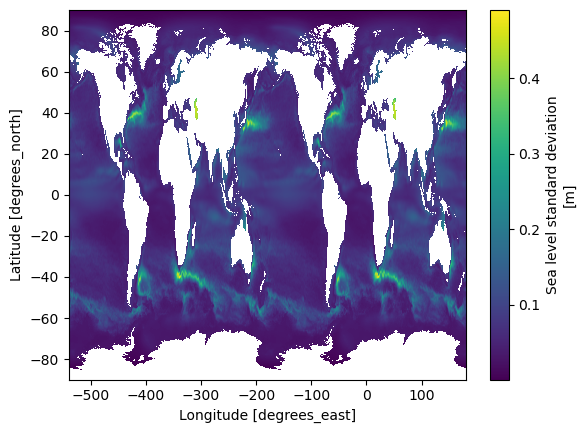

In [39]:
cmems_sla_std_ds.sla.plot()

### Define regions
Match [Kiss et al 2020](https://doi.org/10.5194/gmd-13-401-2020) figs 16, 17, 21, 22, 24

Coordinate ranges copied from
- https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/BarotropicStreamfunction/BarotropicStreamfunction.ipynb
- https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/Southwest_Atlantic/Southwest_atlantic_analysis_v3.ipynb


Text(0.5, 1.0, 'Regions (BUG: incorrect shapes north of 65°N)')

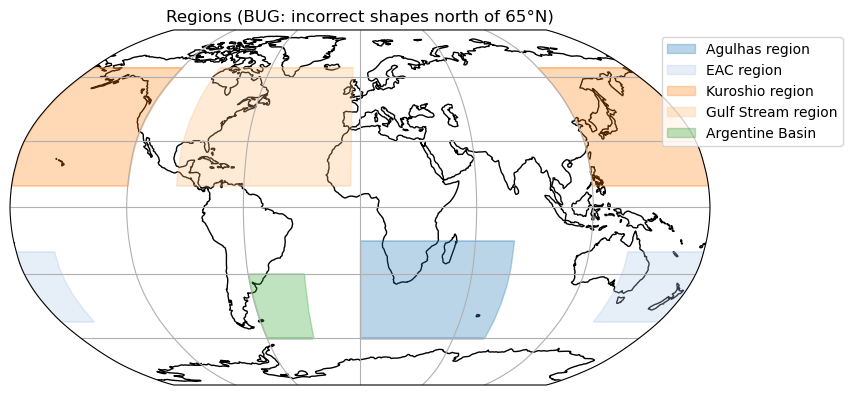

In [40]:
regions = { # [minx, maxx, miny, maxy], using model longitude range (-280 to 80)
    "Agulhas region": [0, 80, -60, -15],  # fig 16 in Kiss et al 2020
    "EAC region": [-220, -160, -52, -20],  # fig 17 in Kiss et al 2020
    "Kuroshio region": [-240, -120, 10, 65],  # fig 21 in Kiss et al 2020
    "Gulf Stream region": [-95, -5, 10, 65],  # fig 22 in Kiss et al 2020
    "Argentine Basin": [-60, -30, -60, -30],  # fig 24 in Kiss et al 2020
    # "Global": [-280, 80, -90, 90],
    # "Arctic": [-280, 80, 65, 90],
    # "Southern Ocean": [-280, 80, -82, -63],
    # "ACC": [-280, 80, -63, -45],
    # "Southern Pacific": [-210, -70, -45, -20],
    # "Tropical Pacific": [-240, -100, -20, 20],
    # "North Pacific": [-240, -100, 20, 65],
    # "South Atlantic": [-60, 20, -45, -20],
    # "Tropical Atlantic": [-70, 20, -20, 20],
    # "North Atlantic": [-100, 0, 20, 65],
    # "Indian": [30, 120, -45, 20],
    # "Aegean Sea": [18, 27.5, 34, 44],
    # "Black Sea": [27.5, 43, 40.5, 48],
    # "Baltic Sea": [13, 30, 53, 58],
    # "Mediterranean Sea": [0, 35, 31, 41],
    # "Red Sea": [33, 44, 12, 29],
    # "Persian Gulf": [47, 56, 24, 31],
    # "White Sea": [31, 41, 63, 68],
}
regions = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in regions.items()}  # convert to dicts

for r, d in regions.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']
try:  # set Global color to white 
    colors[list(regions.keys()).index("Global")] = (1, 1, 1)
except ValueError:
    pass

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.Robinson())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (region, limits) in enumerate(regions.items()):
    ax.add_geometries([geometry.box(**limits)], crs=ccrs.PlateCarree(), color=colors[i], alpha=0.3)
    legend_elements.append(Patch(color=colors[i], alpha=0.3, label=region))

ax.legend(handles=legend_elements, bbox_to_anchor=(1.2, 1.00))
plt.title("Regions (BUG: incorrect shapes north of 65°N)")

## Plot

In [41]:
blue_marble = plt.imread('/g/data/ik11/grids/BlueMarble.tiff')
blue_marble_extent = (-180, 180, -90, 90)

Agulhas region 0 80 -60 -15


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
EAC region -220 -160 -52 -20


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Kuroshio region -240 -120 10 65


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Gulf Stream region -95 -5 10 65


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Argentine Basin -60 -30 -60 -30


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_05.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.


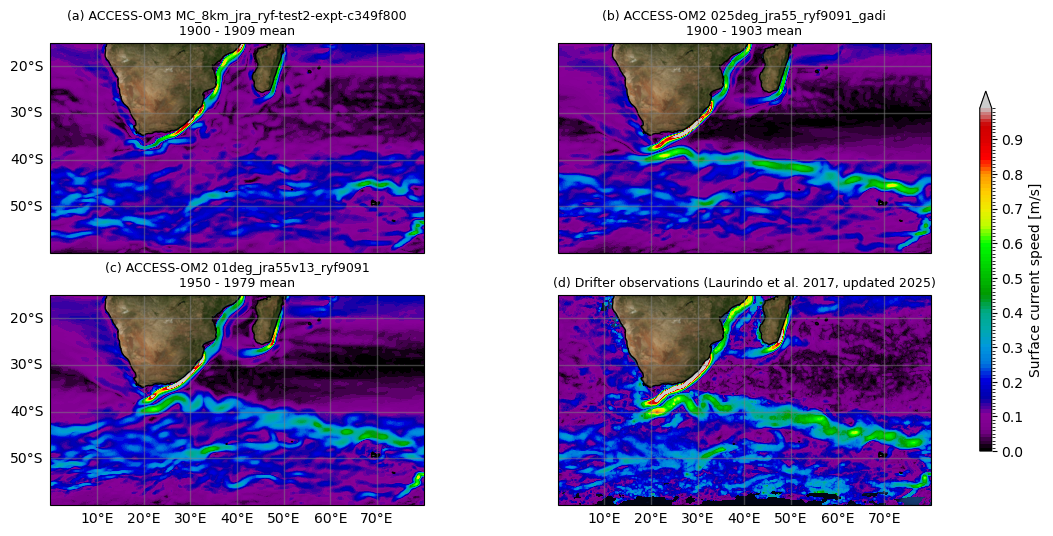

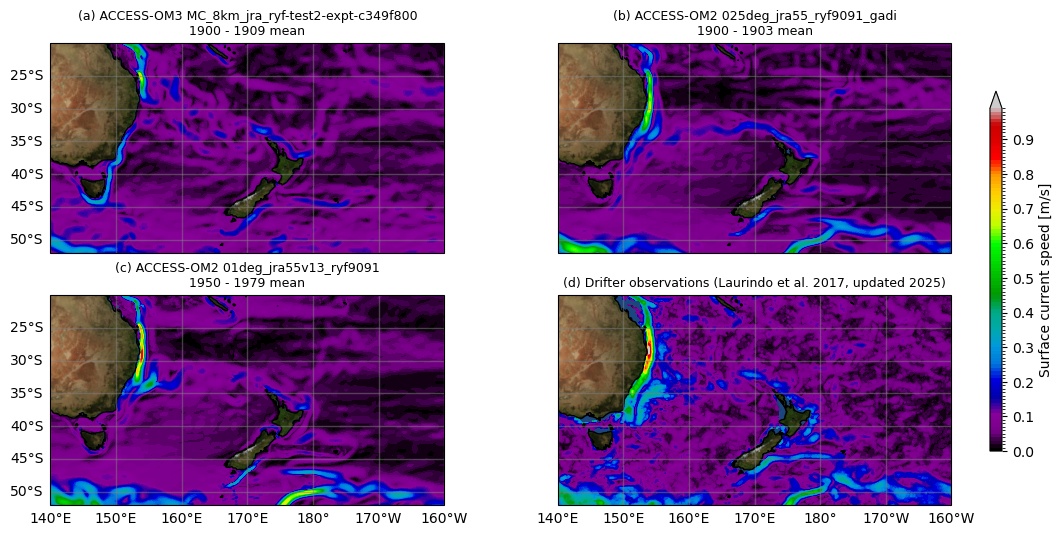

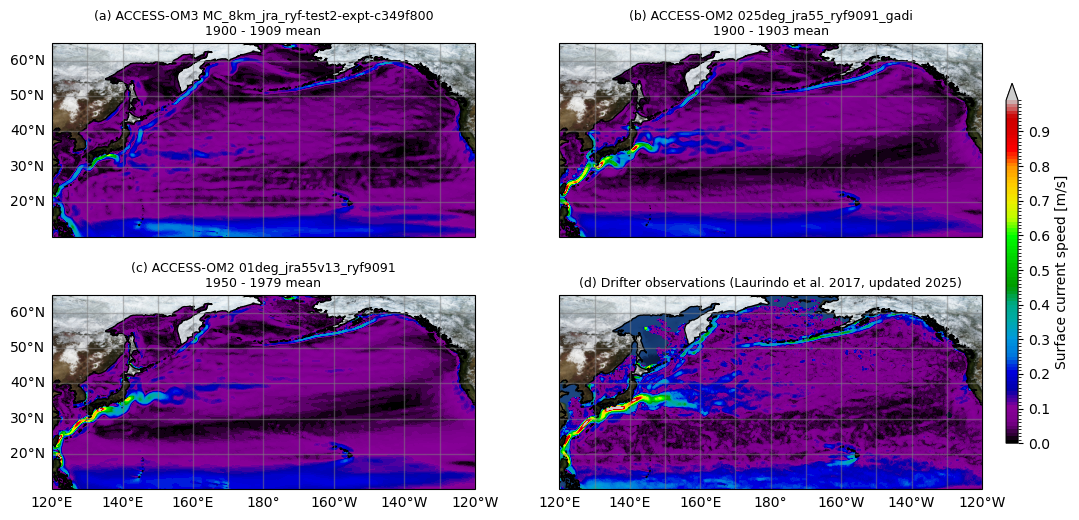

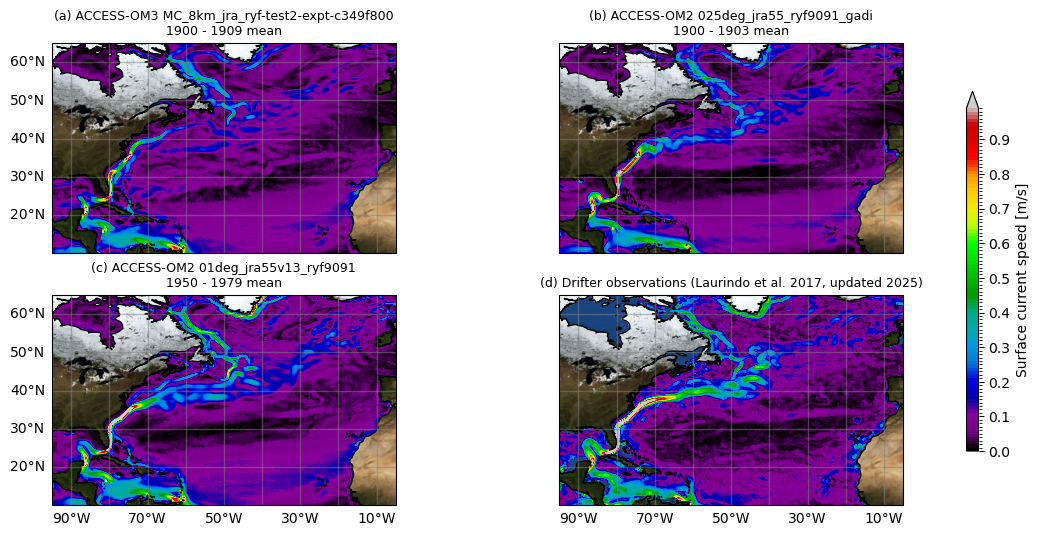

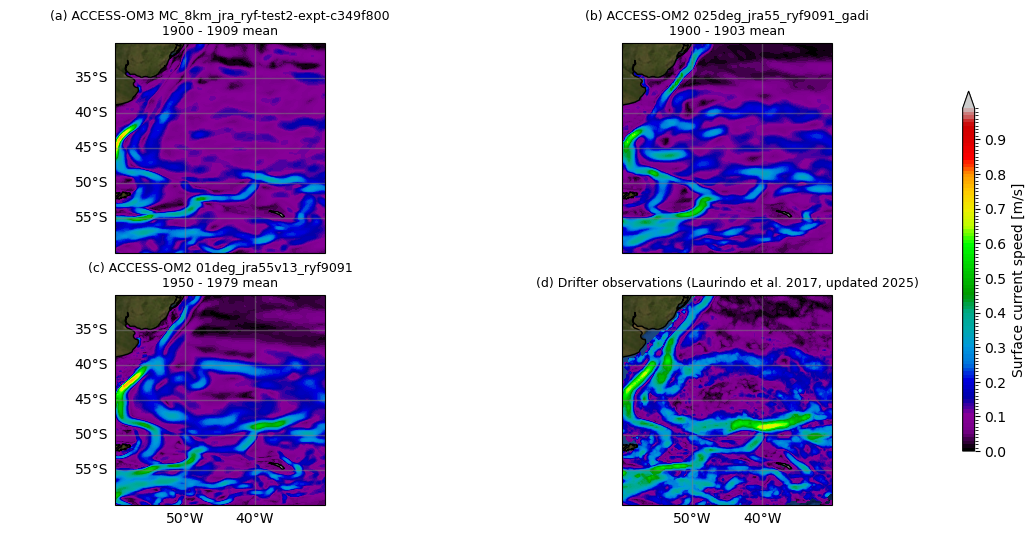

In [42]:
# plot surface current speed
margin = 1
cmp = plt.get_cmap('nipy_spectral')
clev1 = np.arange(0, 1.0, 0.01)
for region, bounds in regions.items():
    # if region == "Kuroshio region":
    #     break
    # if region != "Argentine Basin":
    #     continue
    minx, maxx, miny, maxy = bounds.values()
    print(region, minx, maxx, miny, maxy)
    xslice = slice(minx-margin, maxx+margin)
    yslice = slice(miny-margin, maxy+margin)
    npanels = len(om3data["speed_0"]) + len(om2data["speed_0"]) + 1
    ncols = 2
    nrows = (npanels - 1) // ncols + 1
    proj = ccrs.PlateCarree(central_longitude=(minx+maxx)/2)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3*nrows),
                             subplot_kw=dict(projection=proj,
                                             frame_on=False))
    # plot OM3 data
    for i, (expt, da) in enumerate(om3data["speed_0"].items(), start=1):
        ax = plt.subplot(nrows, ncols, i, projection=proj)
    
        d = da.sel(xq=xslice, yq=yslice)
        p1 = d.plot.contourf(cmap=cmp,
                             levels=clev1,
                             add_colorbar=False,
                             extend='max',
                             transform=ccrs.PlateCarree(),
                            )
        p1.cmap.set_over(color=cmp(255), alpha=None)
        plt.title(f"({chr(ord('a')+i-1)}) ACCESS-OM3 {expt}\n{om3period} mean",
                  fontsize=9)
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color='gray', alpha=0.5, linestyle='-')
        gl.top_labels = False
        gl.right_labels = False
        if i%ncols != 1:
            gl.left_labels = False
        if i + 1 < npanels:
            gl.bottom_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
        plt.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper")
        ax.coastlines(resolution="50m")
        ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())
    
    # plot OM2 data
    for i, (expt, da) in enumerate(om2data["speed_0"].items(), start=i+1):
        ax = plt.subplot(nrows, ncols, i, projection=proj)
    
        d = da.sel(xu_ocean=xslice, yu_ocean=yslice)
        p1 = d.plot.contourf(cmap=cmp,
                             levels=clev1,
                             add_colorbar=False,
                             extend='max',
                             transform=ccrs.PlateCarree(),
                            )
        p1.cmap.set_over(color=cmp(255), alpha=None)
        plt.title(f"({chr(ord('a')+i-1)}) ACCESS-OM2 {expt}\n{om2period[expt]} mean",
                  fontsize=9)
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color='gray', alpha=0.5, linestyle='-')
        gl.top_labels = False
        gl.right_labels = False
        if i%ncols != 1:
            gl.left_labels = False
        if i + 1 < npanels:
            gl.bottom_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
        plt.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper")
        ax.coastlines(resolution="50m")
        ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())
    
    # plot obs
    i += 1
    ax = plt.subplot(nrows, ncols, i, projection=proj)

    d = drifters_ds["speed"].sel(longitude=xslice, latitude=yslice)
    p1 = d.plot.contourf(cmap=cmp,
                         levels=clev1,
                         add_colorbar=False,
                         extend='max',
                         transform=ccrs.PlateCarree(),
                        )
    p1.cmap.set_over(color=cmp(255), alpha=None)
    plt.title(f"({chr(ord('a')+i-1)}) Drifter observations (Laurindo et al. 2017, updated 2025)",
              fontsize=9)
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color='gray', alpha=0.5, linestyle='-')
    gl.top_labels = False
    gl.right_labels = False
    if i%ncols != 1:
        gl.left_labels = False
    if i + 1 < npanels:
        gl.bottom_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
    plt.imshow(
        blue_marble,
        extent=blue_marble_extent,
        transform=ccrs.PlateCarree(),
        origin="upper")
    ax.coastlines(resolution="50m")
    ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())

    ax1 = plt.axes([0.92, 0.2, 0.01, 0.6])
    cb = plt.colorbar(p1, cax=ax1, orientation='vertical', pad=.05)
    cb.ax.set_ylabel('Surface current speed [m/s]')

    mkmd.savefig(fig,"Current Speed", "Model vs drifter current speed (surface). Region: "+region, dpi=150)

Agulhas region 0 80 -60 -15


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_06.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
EAC region -220 -160 -52 -20


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_07.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Kuroshio region -240 -120 10 65


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_08.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Gulf Stream region -95 -5 10 65


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_09.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Argentine Basin -60 -30 -60 -30


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_10.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.


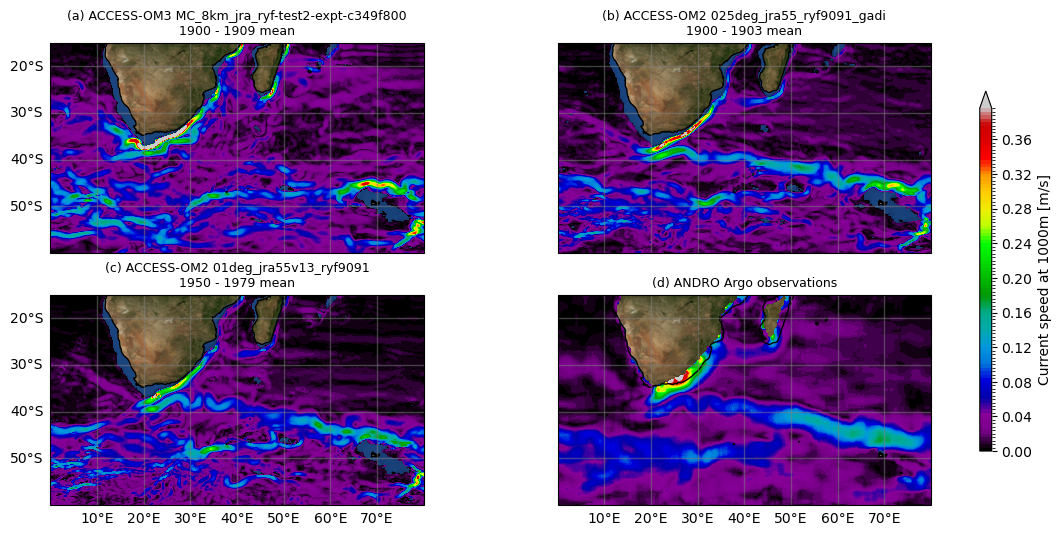

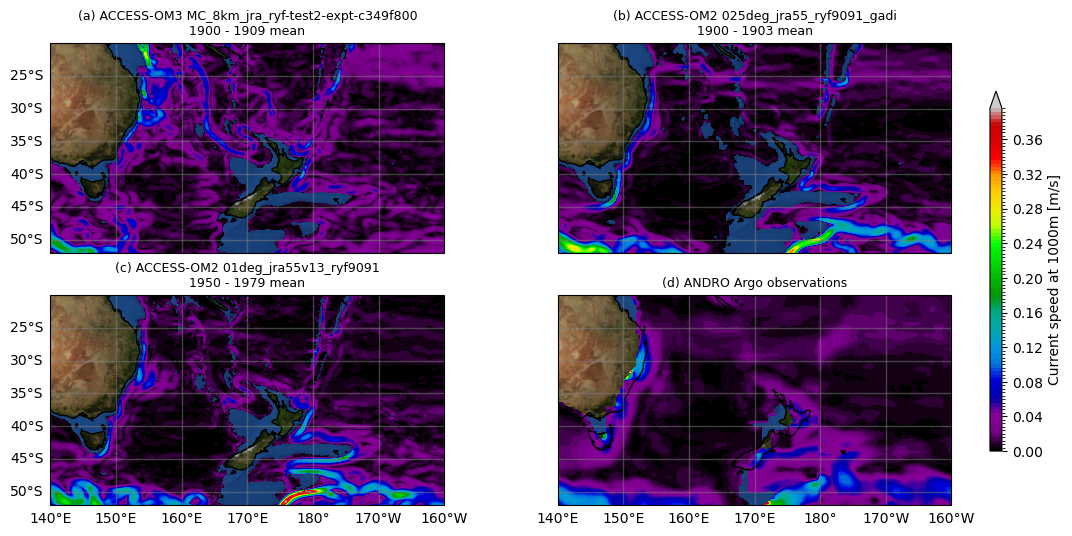

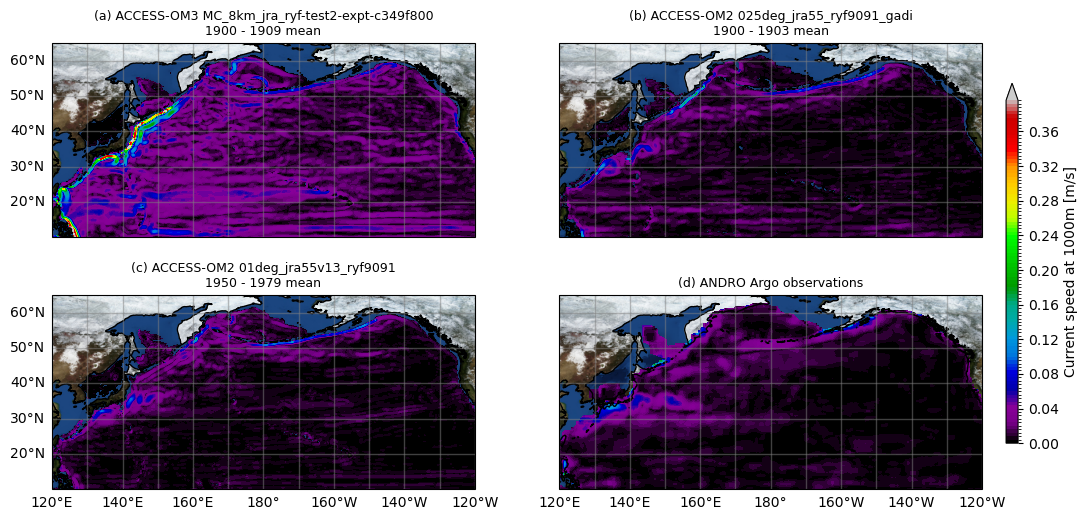

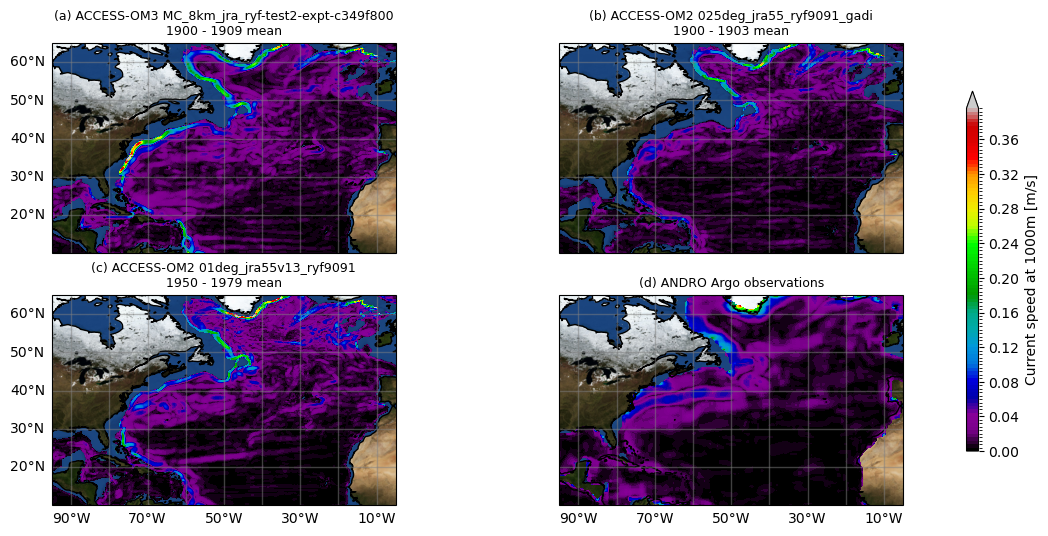

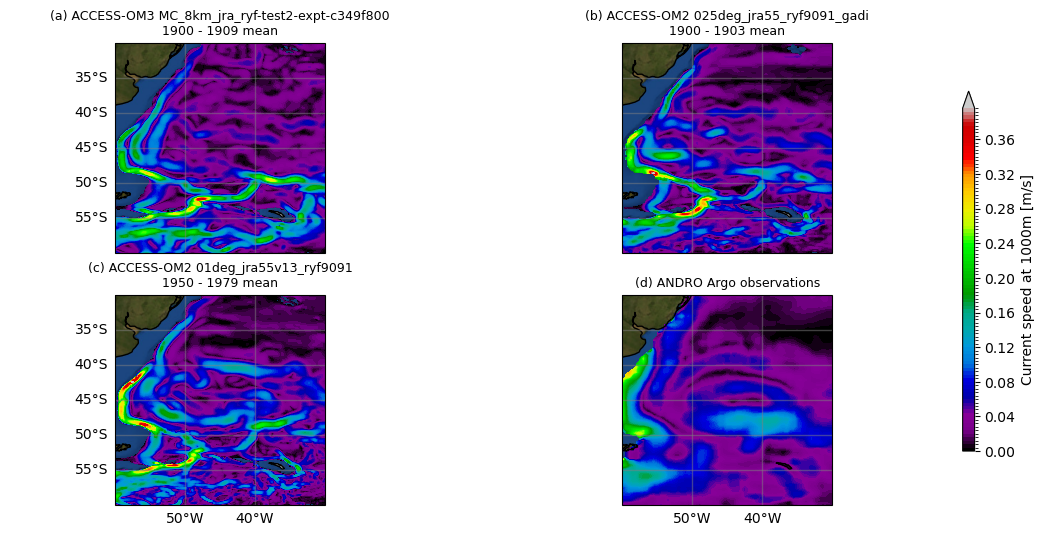

In [43]:
# plot 1000m current speed
margin = 1
cmp = plt.get_cmap('nipy_spectral')
clev1 = np.arange(0, 1.0, 0.01) * 0.4
for region, bounds in regions.items():
    # if region != "Argentine Basin":
    #     continue
    minx, maxx, miny, maxy = bounds.values()
    print(region, minx, maxx, miny, maxy)
    xslice = slice(minx-margin, maxx+margin)
    yslice = slice(miny-margin, maxy+margin)
    npanels = len(om3data["speed_0"]) + len(om2data["speed_0"]) + 1
    ncols = 2
    nrows = (npanels - 1) // ncols + 1
    proj = ccrs.PlateCarree(central_longitude=(minx+maxx)/2)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3*nrows),
                             subplot_kw=dict(projection=proj,
                                             frame_on=False))
    # plot OM3 data
    for i, (expt, da) in enumerate(om3data["speed_1000"].items(), start=1):
        ax = plt.subplot(nrows, ncols, i, projection=proj)
    
        d = da.sel(xq=xslice, yq=yslice)
        p1 = d.plot.contourf(cmap=cmp,
                             levels=clev1,
                             add_colorbar=False,
                             extend='max',
                             transform=ccrs.PlateCarree(),
                            )
        p1.cmap.set_over(color=cmp(255), alpha=None)
        plt.title(f"({chr(ord('a')+i-1)}) ACCESS-OM3 {expt}\n{om3period} mean",
                  fontsize=9)
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color='gray', alpha=0.5, linestyle='-')
        gl.top_labels = False
        gl.right_labels = False
        if i%ncols != 1:
            gl.left_labels = False
        if i + 1 < npanels:
            gl.bottom_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
        plt.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper")
        ax.coastlines(resolution="50m")
        ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())
    
    # plot OM2 data
    for i, (expt, da) in enumerate(om2data["speed_1000"].items(), start=i+1):
        ax = plt.subplot(nrows, ncols, i, projection=proj)
    
        d = da.sel(xu_ocean=xslice, yu_ocean=yslice)
        p1 = d.plot.contourf(cmap=cmp,
                             levels=clev1,
                             add_colorbar=False,
                             extend='max',
                             transform=ccrs.PlateCarree(),
                            )
        p1.cmap.set_over(color=cmp(255), alpha=None)
        plt.title(f"({chr(ord('a')+i-1)}) ACCESS-OM2 {expt}\n{om2period[expt]} mean",
                  fontsize=9)
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color='gray', alpha=0.5, linestyle='-')
        gl.top_labels = False
        gl.right_labels = False
        if i%ncols != 1:
            gl.left_labels = False
        if i + 1 < npanels:
            gl.bottom_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
        plt.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper")
        ax.coastlines(resolution="50m")
        ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())
    
    # plot obs
    i += 1
    ax = plt.subplot(nrows, ncols, i, projection=proj)

    d = andro_ds["speed"].sel(longitude=xslice, latitude=yslice)
    p1 = d.plot.contourf(cmap=cmp,
                         levels=clev1,
                         add_colorbar=False,
                         extend='max',
                         transform=ccrs.PlateCarree(),
                        )
    p1.cmap.set_over(color=cmp(255), alpha=None)
    plt.title(f"({chr(ord('a')+i-1)}) ANDRO Argo observations",
                  fontsize=9)
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color='gray', alpha=0.5, linestyle='-')
    gl.top_labels = False
    gl.right_labels = False
    if i%ncols != 1:
        gl.left_labels = False
    if i + 1 < npanels:
        gl.bottom_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
    plt.imshow(
        blue_marble,
        extent=blue_marble_extent,
        transform=ccrs.PlateCarree(),
        origin="upper")
    ax.coastlines(resolution="50m")
    ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())

    ax1 = plt.axes([0.92, 0.2, 0.01, 0.6])
    cb = plt.colorbar(p1, cax=ax1, orientation='vertical', pad=.05)
    cb.ax.set_ylabel('Current speed at 1000m [m/s]')

    mkmd.savefig(fig,"Current Speed", "Model vs drifter current speed (1000m). Region: "+region, dpi=150)

Agulhas region 0 80 -60 -15


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_11.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
EAC region -220 -160 -52 -20


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_12.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Kuroshio region -240 -120 10 65


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_13.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Gulf Stream region -95 -5 10 65


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_14.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.
Argentine Basin -60 -30 -60 -30


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability_15.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/Currents_streamfunction_variability.md successfully.


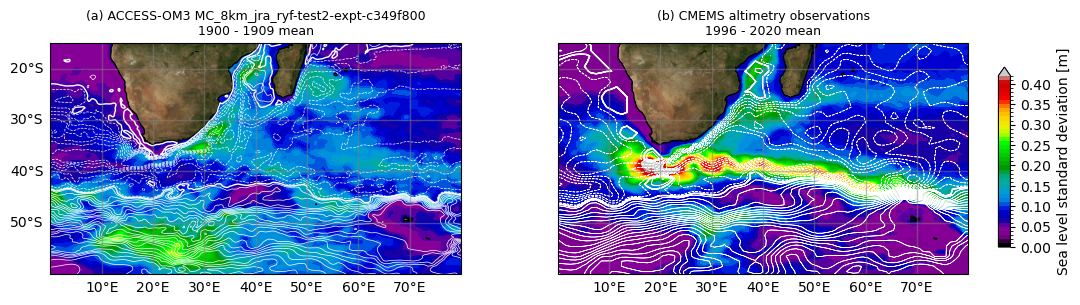

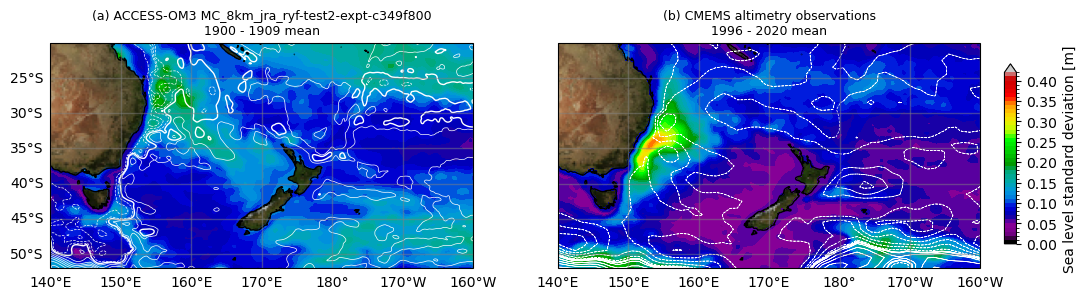

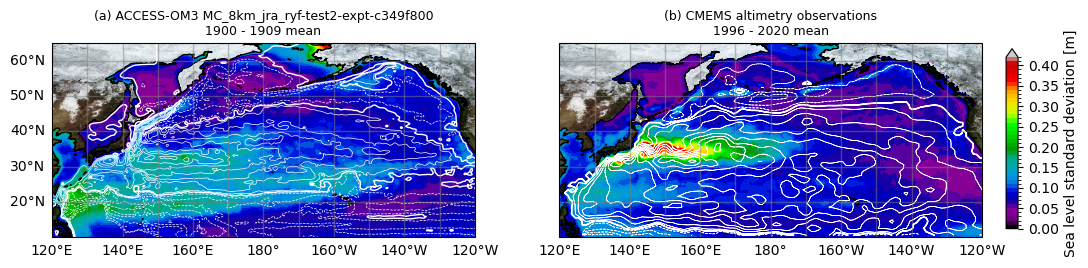

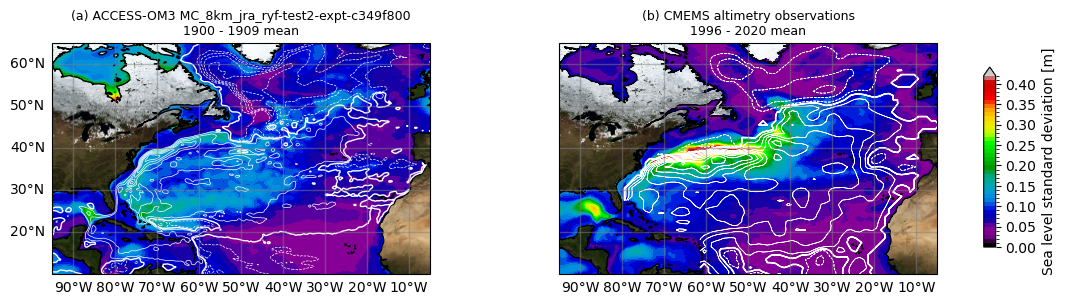

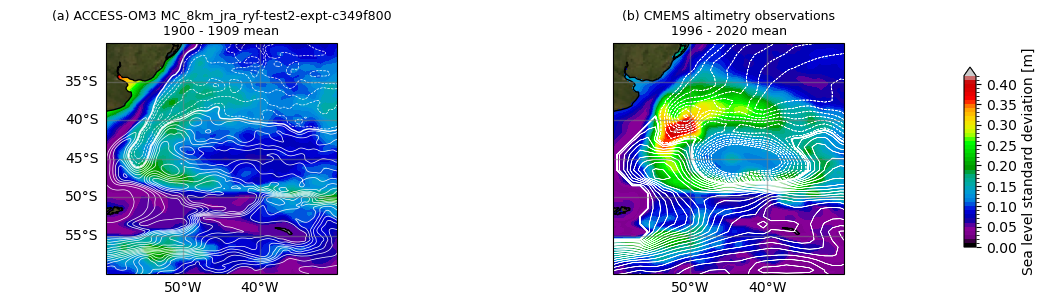

In [44]:
# plot SSH standard deviation and streamfunction
margin = 1
cmp = plt.get_cmap('nipy_spectral')
clev1 = np.arange(0, 0.421, 0.01)
clev2 = np.arange(-75, 300.01, 10)
for region, bounds in regions.items():
    # if region != "Argentine Basin":
    #     continue
    minx, maxx, miny, maxy = bounds.values()
    print(region, minx, maxx, miny, maxy)
    xslice = slice(minx-margin, maxx+margin)
    yslice = slice(miny-margin, maxy+margin)
    npanels = len(om3data["ssh_std"]) + len(om2data["ssh_std"]) + 1
    ncols = 2
    nrows = (npanels - 1) // ncols + 1
    proj = ccrs.PlateCarree(central_longitude=(minx+maxx)/2)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3*nrows),
                             subplot_kw=dict(projection=proj,
                                             frame_on=False))
    # plot OM3 data
    for i, (expt, da) in enumerate(om3data["ssh_std"].items(), start=1):
        ax = plt.subplot(nrows, ncols, i, projection=proj)
    
        d = da.sel(xh=xslice, yh=yslice)
        p1 = d.plot.contourf(cmap=cmp,
                             levels=clev1,
                             add_colorbar=False,
                             extend='max',
                             transform=ccrs.PlateCarree(),
                            )
        p1.cmap.set_over(color=cmp(255), alpha=None)
        om3data['psi'][expt].plot.contour(levels=clev2, colors='w', linewidths=0.5, transform=ccrs.PlateCarree())
        om3data['psi'][expt].plot.contour(levels=[0.0], colors='w', linewidths=1.0, transform=ccrs.PlateCarree())
        plt.title(f"({chr(ord('a')+i-1)}) ACCESS-OM3 {expt}\n{om3period} mean",
                  fontsize=9)
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color='gray', alpha=0.5, linestyle='-')
        gl.top_labels = False
        gl.right_labels = False
        if i%ncols != 1:
            gl.left_labels = False
        if i + 1 < npanels:
            gl.bottom_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
        plt.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper")
        ax.coastlines(resolution="50m")
        ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())
    
    # plot OM2 data
    for i, (expt, da) in enumerate(om2data["ssh_std"].items(), start=i+1):
        ax = plt.subplot(nrows, ncols, i, projection=proj)
    
        d = da.sel(xt_ocean=xslice, yt_ocean=yslice)
        p1 = d.plot.contourf(cmap=cmp,
                             levels=clev1,
                             add_colorbar=False,
                             extend='max',
                             transform=ccrs.PlateCarree(),
                            )
        p1.cmap.set_over(color=cmp(255), alpha=None)
        om2data['psi'][expt].plot.contour(levels=clev2, colors='w', linewidths=0.5, transform=ccrs.PlateCarree())
        om2data['psi'][expt].plot.contour(levels=[0.0], colors='w', linewidths=1.0, transform=ccrs.PlateCarree())
        plt.title(f"({chr(ord('a')+i-1)}) ACCESS-OM2 {expt}\n{om2period[expt]} mean",
                  fontsize=9)
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color='gray', alpha=0.5, linestyle='-')
        gl.top_labels = False
        gl.right_labels = False
        if i%ncols != 1:
            gl.left_labels = False
        if i + 1 < npanels:
            gl.bottom_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
        plt.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper")
        ax.coastlines(resolution="50m")
        ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())
    
    # plot obs
    i += 1
    ax = plt.subplot(nrows, ncols, i, projection=proj)

    d = cmems_sla_std_ds["sla"].sel(longitude=xslice, latitude=yslice)
    p1 = d.plot.contourf(cmap=cmp,
                         levels=clev1,
                         add_colorbar=False,
                         extend='max',
                         transform=ccrs.PlateCarree(),
                        )
    p1.cmap.set_over(color=cmp(255), alpha=None)
    psi_ds["psi"].plot.contour(levels=clev2, colors='w', linewidths=0.5, transform=ccrs.PlateCarree())
    psi_ds["psi"].plot.contour(levels=[0.0], colors='w', linewidths=1.0, transform=ccrs.PlateCarree())
    plt.title(f"({chr(ord('a')+i-1)}) CMEMS altimetry observations\n{obsperiod} mean",
                  fontsize=9)
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color='gray', alpha=0.5, linestyle='-')
    gl.top_labels = False
    gl.right_labels = False
    if i%ncols != 1:
        gl.left_labels = False
    if i + 1 < npanels:
        gl.bottom_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-270, 180, 10))
    plt.imshow(
        blue_marble,
        extent=blue_marble_extent,
        transform=ccrs.PlateCarree(),
        origin="upper")
    ax.coastlines(resolution="50m")
    ax.set_extent(bounds.values(), crs=ccrs.PlateCarree())

    ax1 = plt.axes([0.92, 0.2, 0.01, 0.6])
    cb = plt.colorbar(p1, cax=ax1, orientation='vertical', pad=.05)
    cb.ax.set_ylabel('Sea level standard deviation [m]')

    mkmd.savefig(fig,"Sea level standard deviation and barotropic streamfunction", "Model vs altimeter sea surface height standard deviation (m) and barotropic streamfunction. Region: "+region, dpi=150)
    